## Exercise 1


In [1]:
import matplotlib.pyplot as plt
from pyod.utils.data import generate_data

In [4]:
x_train, x_test, y_train, y_test = generate_data(n_train=400, n_test=100, n_features=2, contamination=0.1, random_state=42)

inliers = x_train[y_train == 0]
outliers = x_train[y_train == 1]

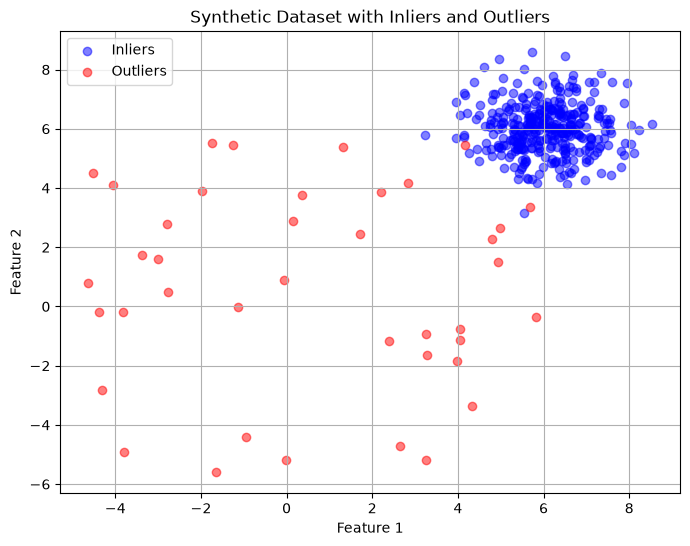

In [5]:
plt.figure(figsize=(8, 6))
plt.scatter(inliers[:, 0], inliers[:, 1], c='blue', label='Inliers', alpha=0.5)
plt.scatter(outliers[:, 0], outliers[:, 1], c='red', label='Outliers', alpha=0.5)

plt.title('Synthetic Dataset with Inliers and Outliers')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()


## Exercise 2

In [7]:
import matplotlib.pyplot as plt
from pyod.models.knn import KNN
from sklearn.metrics import confusion_matrix, roc_curve, auc

In [16]:
contamination_rate = 0.3
model = KNN(contamination=contamination_rate)
model.fit(x_train)

,contamination,0.3
,n_neighbors,5
,method,'largest'
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'minkowski'
,p,2
,metric_params,None
,n_jobs,1
Name,Type,Value


In [17]:
y_train_pred = model.labels_  
y_test_pred = model.predict(x_test)

In [18]:
y_train_scores = model.decision_scores_
y_test_scores = model.decision_function(x_test)

In [19]:
def evaluate_matrix(y_true, y_pred, split_name='Train'):

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    tnr = tn / (tn + fp) if (tn + fp) > 0 else 0
    ba = (tpr + tnr) / 2

    print(f"--- {split_name} Evaluation Metrics ---")
    print(f"True Positives (TP): {tp}")
    print(f"True Negatives (TN): {tn}")
    print(f"False Positives (FP): {fp}")
    print(f"False Negatives (FN): {fn}")
    print(f"True Positive Rate (TPR): {tpr:.4f}")
    print(f"True Negative Rate (TNR): {tnr:.4f}")
    print(f"Balanced Accuracy (BA): {ba:.4f}")

evaluate_matrix(y_train, y_train_pred, 'Train')
evaluate_matrix(y_test, y_test_pred, 'Test')

--- Train Evaluation Metrics ---
True Positives (TP): 40
True Negatives (TN): 280
False Positives (FP): 80
False Negatives (FN): 0
True Positive Rate (TPR): 1.0000
True Negative Rate (TNR): 0.7778
Balanced Accuracy (BA): 0.8889
--- Test Evaluation Metrics ---
True Positives (TP): 9
True Negatives (TN): 75
False Positives (FP): 15
False Negatives (FN): 1
True Positive Rate (TPR): 0.9000
True Negative Rate (TNR): 0.8333
Balanced Accuracy (BA): 0.8667


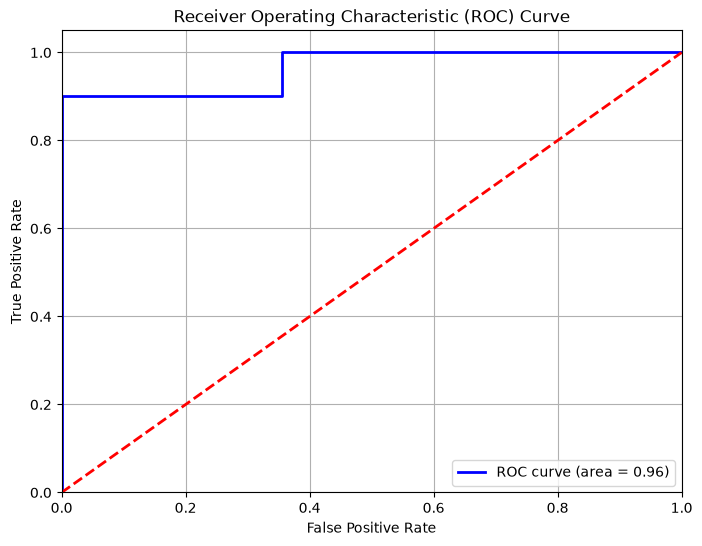

In [20]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


## Exercise 3

In [1]:
import numpy as np
from pyod.utils.data import generate_data
from sklearn.metrics import confusion_matrix

contamination_rate = 0.1
x_train, x_test, y_train, y_test = generate_data(
    n_train=1000,
    n_test=0,
    n_features=1,
    contamination=contamination_rate,
    random_state=42
)

z_scores = np.abs((x_train[:, 0] - np.mean(x_train[:, 0])) / np.std(x_train[:, 0]))
z_threshold = np.quantile(z_scores, 1 - contamination_rate)

y_pred = (z_scores > z_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_train, y_pred, labels=[0, 1]).ravel()

tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
tnr = tn / (tn + fp) if (tn + fp) > 0 else 0
ba = (tpr + tnr) / 2

print(f"Z-score threshold: {z_threshold:.4f}")
print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positive Rate (TPR): {tpr:.4f}")
print(f"True Negative Rate (TNR): {tnr:.4f}")
print(f"Balanced Accuracy (BA): {ba:.4f}")


Z-score threshold: 0.9298
True Positives (TP): 71
True Negatives (TN): 871
False Positives (FP): 29
False Negatives (FN): 29
True Positive Rate (TPR): 0.7100
True Negative Rate (TNR): 0.9678
Balanced Accuracy (BA): 0.8389


## Exercise 4

In [2]:
import numpy as np
from sklearn.metrics import confusion_matrix

contamination_rate = 0.1
n_samples = 1000
n_outliers = int(n_samples * contamination_rate)
n_inliers = n_samples - n_outliers

mean = np.array([2, -1, 3])
covariance = np.array([
    [2.0, 0.5, 0.3],
    [0.5, 1.5, 0.2],
    [0.3, 0.2, 1.0]
])

L = np.linalg.cholesky(covariance)

x_inliers = np.random.randn(n_inliers, 3)
x_outliers = np.random.randn(n_outliers, 3) + 5

inliers = x_inliers @ L.T + mean
outliers = x_outliers @ L.T + mean

x_train = np.vstack((inliers, outliers))
y_train = np.concatenate((np.zeros(n_inliers), np.ones(n_outliers))).astype(int)

z_scores = np.abs((x_train - np.mean(x_train, axis=0)) / np.std(x_train, axis=0))
anomaly_scores = np.max(z_scores, axis=1)
z_threshold = np.quantile(anomaly_scores, 1 - contamination_rate)

y_pred = (anomaly_scores > z_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(y_train, y_pred, labels=[0, 1]).ravel()

tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
tnr = tn / (tn + fp) if (tn + fp) > 0 else 0
ba = (tpr + tnr) / 2

print(f"Z-score threshold: {z_threshold:.4f}")
print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positive Rate (TPR): {tpr:.4f}")
print(f"True Negative Rate (TNR): {tnr:.4f}")
print(f"Balanced Accuracy (BA): {ba:.4f}")


Z-score threshold: 1.9766
True Positives (TP): 99
True Negatives (TN): 899
False Positives (FP): 1
False Negatives (FN): 1
True Positive Rate (TPR): 0.9900
True Negative Rate (TNR): 0.9989
Balanced Accuracy (BA): 0.9944
